# Big 5 Leagues: factor analysis, outliers and clustering

###Imports

In [ ]:
#Necessary Installs
!pip install factor_analyzer
!pip install pingouin pandas numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 2.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42655 sha256=5cf4d50253f6f5b635dd1bbd92c0d8532eb2d980b6f11aa056e8dac752f3d8be
  Stored in directory: /root/.cache/pip/wheels/a2/af/06/f4d4ed4d9d714fda437fb1583629417319603c2266e7b233cc
Successfully built factor_analyzer
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.4/204.4 kB 11.9 MB/s eta 0:00:00


In [ ]:
#Necessary Imports
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.rotator import Rotator
from factor_analyzer import FactorAnalyzer
import pingouin as pg
from numpy.linalg import inv
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

In [ ]:
!pip install feature-engine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 4.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from feature_engine.outliers import Winsorizer
from sklearn.cluster import KMeans
from sklearn.metrics import explained_variance_score

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
import plotly.express as px

### Exploratory Analysis + FA

In [ ]:
#Import data

df_8 = pd.read_excel("Hidden Gems Group Big5.xlsx", sheet_name="Dataset", index_col = "Player")
df_8

,Gls,Sh,G/Sh,G-xG,Ast,A-xAG,KP,PPA,CrsPA,SCA,GCA,Att 3rd,Tkl+Int,Att Pen,TOSucc,PrgC,Mis,Dis,On-Off,AeWon
Player,,,,,,,,,,,,,,,,,,,,
Alexander Isak,0.75,3.10,0.20,0.09,0.20,0.06,1.34,1.01,0.03,3.01,0.46,0.23,0.49,6.18,1.37,2.71,2.16,1.80,0.67,0.85
Antoine Semenyo,0.31,3.51,0.09,0.03,0.14,-0.02,1.29,1.26,0.22,3.71,0.37,0.37,1.85,5.37,1.94,3.93,2.36,2.16,-0.25,1.85
Beto,0.47,2.88,0.16,-0.01,0.00,-0.07,0.71,0.47,0.06,1.53,0.06,0.24,1.06,5.06,1.12,0.88,4.18,2.18,0.50,5.82
Brennan Johnson,0.45,2.23,0.20,0.02,0.12,0.03,0.79,1.45,0.25,1.90,0.29,0.41,1.78,5.17,0.79,2.48,1.07,0.70,0.40,0.29
Bryan Mbeumo,0.53,2.08,0.19,0.20,0.18,-0.03,1.85,1.56,0.50,3.80,0.53,0.42,1.66,4.43,1.37,3.43,2.80,1.24,4.39,0.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Roberto Piccoli,0.29,2.80,0.09,-0.08,0.03,0.00,0.37,0.20,0.00,1.64,0.23,0.14,0.46,4.15,0.40,0.86,3.29,1.33,-1.47,3.17
Romelu Lukaku,0.44,1.90,0.18,0.03,0.32,0.19,1.11,0.35,0.03,2.41,0.51,0.06,0.16,4.53,0.19,0.98,1.74,1.68,1.20,1.33
Santiago Castro,0.31,2.43,0.13,0.01,0.16,0.04,1.10,0.31,0.00,2.71,0.43,0.20,0.82,3.96,0.71,0.67,2.75,2.51,-0.20,1.45


In [ ]:
df_8=df_8.drop(columns="A-xAG")
df_8=df_8.drop(columns="KP")
df_8=df_8.drop(columns="On-Off")

In [ ]:
#Summary Statistics

summary = df_8.describe().T
summary["variance"] = df_8.var()
summary["median"] = df_8.median()

print("Summary Statistics")
summary

Summary Statistics


,count,mean,std,min,25%,50%,75%,max,variance,median
Gls,138.0,0.420435,0.234053,0.00,0.2800,0.365,0.5300,1.15,0.054781,0.365
Sh,138.0,2.559928,0.817483,1.08,2.0425,2.415,3.0550,5.00,0.668278,2.415
G/Sh,138.0,0.144348,0.059511,0.00,0.1000,0.140,0.1800,0.30,0.003542,0.140
G-xG,138.0,0.015362,0.118119,-0.31,-0.0600,0.020,0.0875,0.44,0.013952,0.020
Ast,138.0,0.150290,0.112742,0.00,0.0700,0.120,0.2000,0.56,0.012711,0.120
PPA,138.0,0.813623,0.651065,0.00,0.3425,0.530,1.1775,3.00,0.423886,0.530
CrsPA,138.0,0.156087,0.209854,0.00,0.0000,0.070,0.1975,1.06,0.044039,0.070
SCA,138.0,2.624203,1.144531,0.50,1.7900,2.350,3.2875,5.93,1.309950,2.350
GCA,138.0,0.345072,0.203406,0.00,0.2100,0.300,0.4600,1.30,0.041374,0.300
Att 3rd,138.0,0.233551,0.136600,0.00,0.1400,0.200,0.3100,0.66,0.018660,0.200


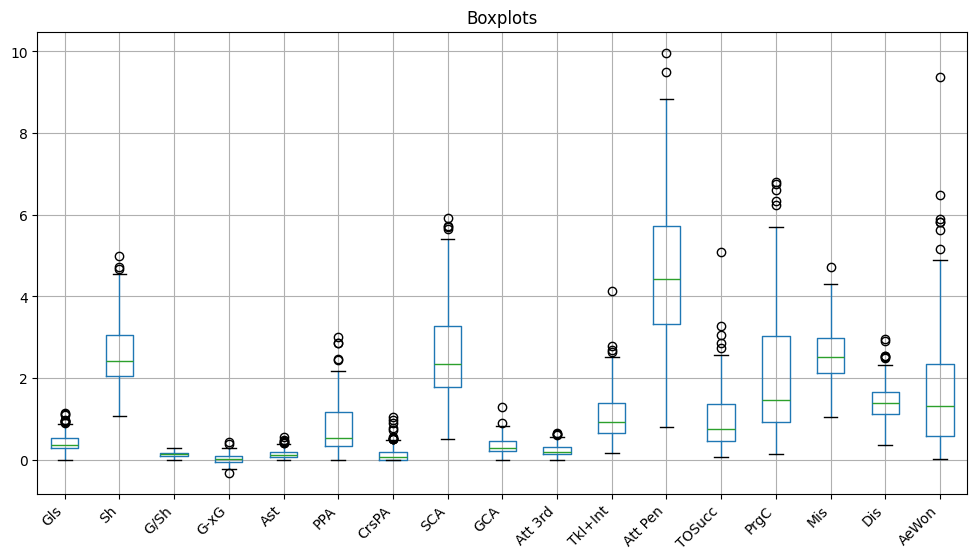

In [ ]:
plt.figure(figsize=(12, 6))

df_8.boxplot()

plt.title("Boxplots")

plt.xticks(rotation=45, ha="right")

plt.show()

In [ ]:
#Standardize data
scaler = StandardScaler()
df_8_standardized = scaler.fit_transform(df_8)

df_8_standardized = pd.DataFrame(df_8_standardized, columns= df_8.columns, index=df_8.index)
df_8_standardized

,Gls,Sh,G/Sh,G-xG,Ast,PPA,CrsPA,SCA,GCA,Att 3rd,Tkl+Int,Att Pen,TOSucc,PrgC,Mis,Dis,AeWon
Player,,,,,,,,,,,,,,,,,
Alexander Isak,1.413209,0.663060,0.938567,0.634188,0.442524,0.302723,-0.603021,0.338307,0.567073,-0.026088,-0.905558,0.936510,0.453393,0.325589,-0.541453,0.796505,-0.582968
Antoine Semenyo,-0.473555,1.166426,-0.916569,0.124375,-0.091601,0.688108,0.305669,0.952139,0.122997,1.002535,1.238175,0.497403,1.186012,1.063158,-0.263423,1.550944,0.049895
Beto,0.212541,0.392961,0.263972,-0.215501,-1.337893,-0.529709,-0.459544,-0.959511,-1.406599,0.047385,-0.007082,0.329350,0.132069,-0.780765,2.266650,1.592858,2.562362
Brennan Johnson,0.126779,-0.405060,0.938567,0.039406,-0.269643,0.981000,0.449147,-0.635056,-0.271738,1.296428,1.127836,0.388982,-0.292079,0.186539,-2.056717,-1.508727,-0.937371
Bryan Mbeumo,0.469827,-0.589218,0.769918,1.568847,0.264482,1.150569,1.644793,1.031061,0.912466,1.369901,0.938683,-0.012178,0.453393,0.760876,0.348243,-0.377068,-0.551325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Roberto Piccoli,-0.559317,0.294743,-0.916569,-0.810283,-1.070830,-0.945924,-0.746499,-0.863051,-0.567788,-0.687346,-0.952847,-0.163968,-0.793345,-0.792856,1.029416,-0.188458,0.885275
Romelu Lukaku,0.083898,-0.810209,0.601269,0.124375,1.510774,-0.714694,-0.603021,-0.187835,0.813782,-1.275131,-1.425729,0.042033,-1.063257,-0.720309,-1.125316,0.545025,-0.279194
Santiago Castro,-0.473555,-0.159515,-0.241974,-0.045563,0.086441,-0.776355,-0.746499,0.075236,0.419048,-0.246508,-0.385388,-0.266968,-0.394903,-0.907724,0.278735,2.284427,-0.203250


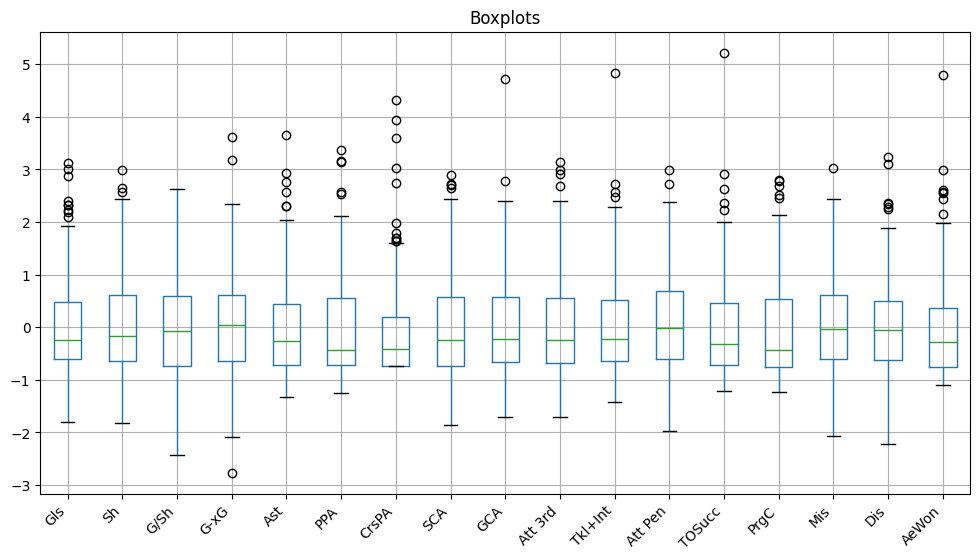

In [ ]:
plt.figure(figsize=(12, 6))

df_8_standardized.boxplot()

plt.title("Boxplots")

plt.xticks(rotation=45, ha="right")

plt.show()

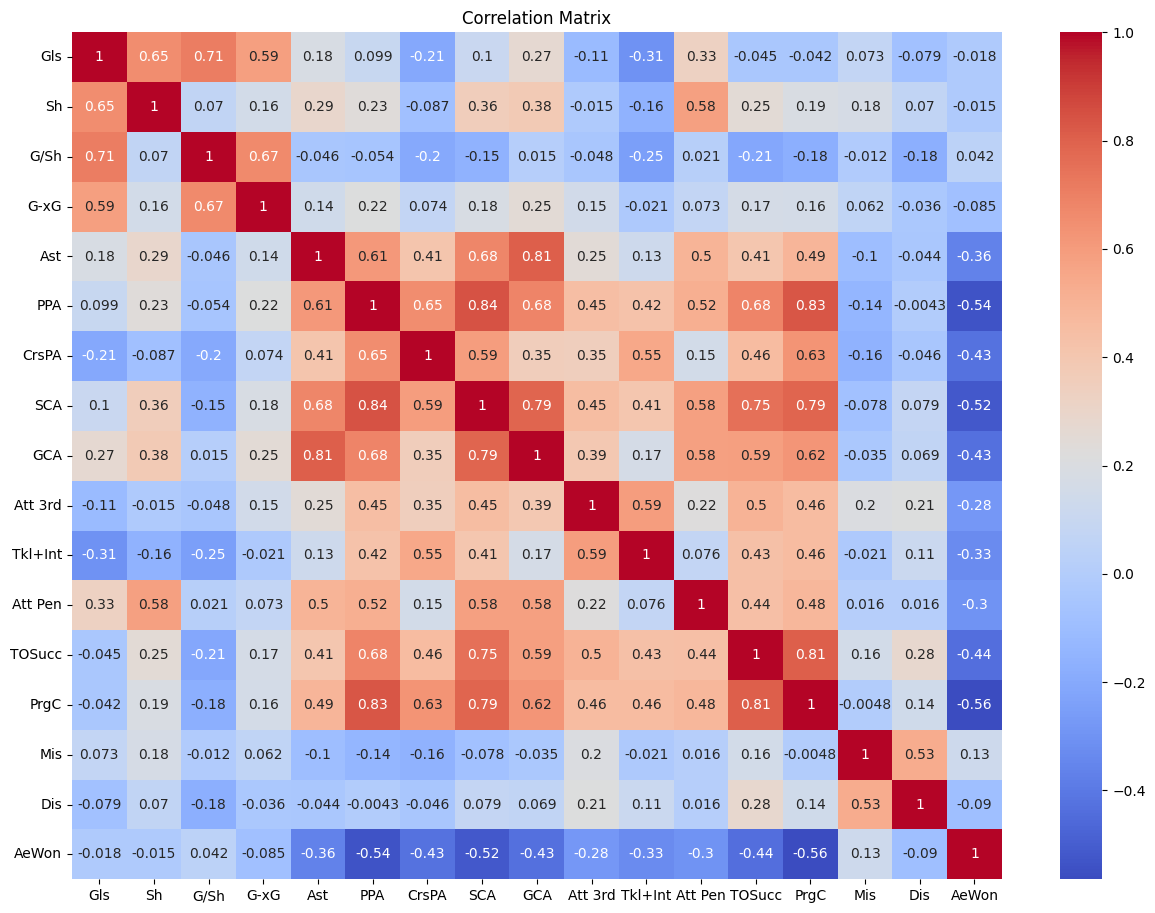

In [ ]:
#Correlation Matrix

corr_matrix = df_8_standardized.corr()

plt.figure(figsize=(15, 11))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

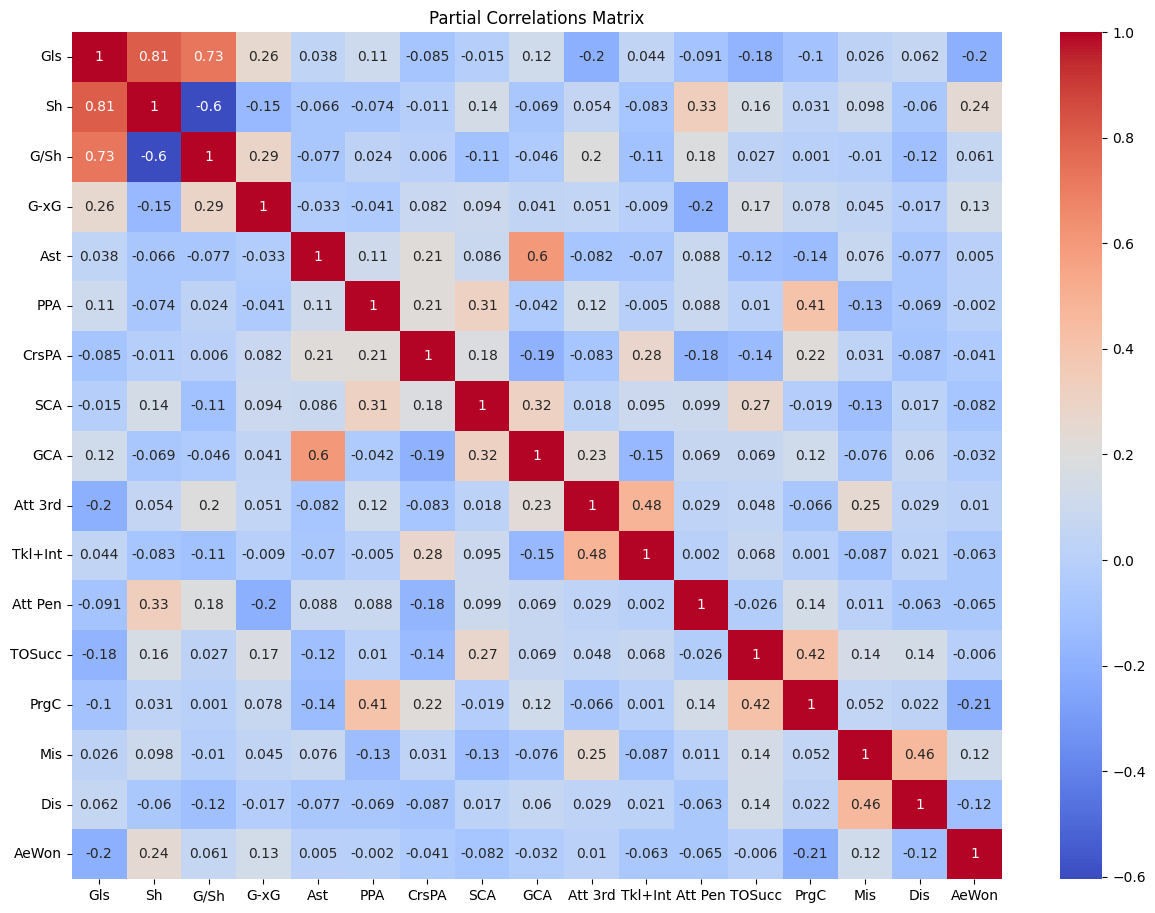

In [ ]:
#Partial correlations

partial_corr_matrix = pd.DataFrame(index=df_8_standardized.columns, columns=df_8_standardized.columns)

for var1 in df_8_standardized.columns:
    for var2 in df_8_standardized.columns:
        if var1 == var2:
            partial_corr_matrix.loc[var1, var2] = 1.0
        else:
            covariates = [col for col in df_8_standardized.columns if col not in [var1, var2]]
            result = pg.partial_corr(data=df_8_standardized, x=var1, y=var2, covar=covariates)
            partial_corr_matrix.loc[var1, var2] = result['r'].values[0]

partial_corr_matrix = partial_corr_matrix.astype(float)


plt.figure(figsize=(15, 11))
sns.heatmap(partial_corr_matrix.round(3), annot=True, cmap='coolwarm')
plt.title('Partial Correlations Matrix')
plt.show()

In [ ]:
#KMO
kmo_all, kmo_model = calculate_kmo(df_8_standardized)

#KMO Overall
print(f"KMO Overall: {kmo_model:.2f}")

kmo_all_series = pd.Series(kmo_all, index=df_8.columns)
print("\nIndividual KMO:")
print(kmo_all_series.round(2))

KMO Overall: 0.81

Individual KMO:
Gls        0.54
Sh         0.52
G/Sh       0.52
G-xG       0.79
Ast        0.84
PPA        0.92
CrsPA      0.87
SCA        0.92
GCA        0.85
Att 3rd    0.80
Tkl+Int    0.82
Att Pen    0.89
TOSucc     0.89
PrgC       0.89
Mis        0.55
Dis        0.64
AeWon      0.90
dtype: float64


In [ ]:
#Initialize FA
fa = FactorAnalyzer()
fa.fit(df_8_standardized)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(rotation_kwargs={})

In [ ]:
#Kaiser Criterion

eigenvalues, _ = fa.get_eigenvalues()
print("Eigenvalues:\n", eigenvalues)

Eigenvalues:
 [6.30026306 2.91442416 1.79446712 1.52661072 0.77081699 0.69953177
 0.6181248  0.48479115 0.42726227 0.3531401  0.27591681 0.22580784
 0.17500045 0.1478054  0.13838813 0.09340218 0.05424706]


In [ ]:
#Pearson Criterion

variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(variance_ratio)
print("Cumulative variance:")
print(cumulative_variance)

Cumulative variance:
[0.37060371 0.54204042 0.64759731 0.73739794 0.78274012 0.82388905
 0.86024933 0.88876646 0.91389953 0.93467248 0.95090288 0.96418569
 0.97447984 0.98317427 0.99131475 0.996809   1.        ]


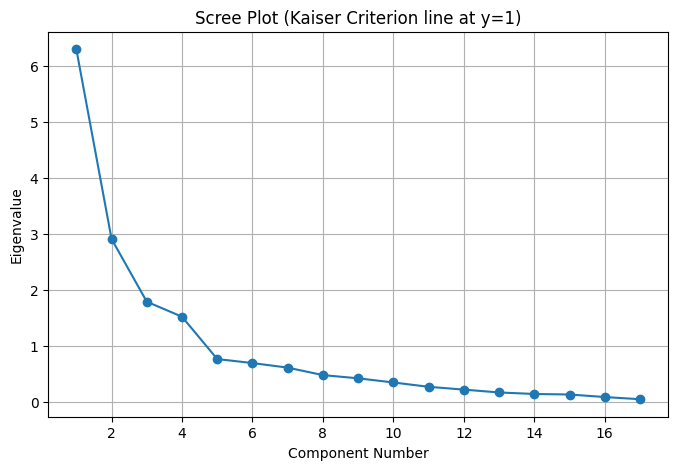

In [ ]:
#Scree Plot

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o')
plt.title('Scree Plot (Kaiser Criterion line at y=1)')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()

In [ ]:
#Perform FA with the number of factors you want to retain

n_factors = 3
fa = FactorAnalyzer(n_factors, rotation= None, method="principal")
fa.fit(df_8_standardized)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(method='principal', rotation=None, rotation_kwargs={})

In [ ]:
#Loadings

loadings = fa.loadings_

loadings_df = pd.DataFrame(loadings, index=df_8_standardized.columns, columns=["F1", "F2", "F3"])
loadings_df

,F1,F2,F3
Gls,0.111013,0.935185,0.034345
Sh,0.333771,0.614339,0.284233
G/Sh,-0.114367,0.736473,-0.152771
G-xG,0.226964,0.606980,-0.044585
Ast,0.711406,0.189860,-0.178724
PPA,0.901420,-0.004298,-0.169047
CrsPA,0.657035,-0.357155,-0.281499
SCA,0.931680,0.019954,-0.046908
GCA,0.820993,0.258123,-0.026144
Att 3rd,0.570796,-0.230990,0.260214


In [ ]:
#Varimax Rotation

rotator = Rotator(method= "Varimax")
rotated_loadings = rotator.fit_transform(loadings)

rotated_df = pd.DataFrame(rotated_loadings, index=df_8_standardized.columns, columns=["F1", "F2", "F3"])

print("Rotated Loadings (Varimax):")
rotated_df

Rotated Loadings (Varimax):


,F1,F2,F3
Gls,-0.015205,0.942255,-0.000305
Sh,0.222430,0.663094,0.283610
G/Sh,-0.193935,0.708711,-0.197302
G-xG,0.149407,0.629935,-0.052770
Ast,0.694513,0.276903,-0.122732
PPA,0.906336,0.110371,-0.086753
CrsPA,0.721736,-0.275746,-0.203857
SCA,0.921375,0.142741,0.036323
GCA,0.779214,0.364545,0.035681
Att 3rd,0.568457,-0.143247,0.321269


In [ ]:
#Quartimax Rotation

rotator = Rotator(method= "Quartimax")
rotated_loadings = rotator.fit_transform(loadings)

rotated_df = pd.DataFrame(rotated_loadings, index=df_8_standardized.columns, columns=["F1", "F2", "F3"])

print("Rotated Loadings (Quartimax):")
rotated_df

Rotated Loadings (Quartimax):


,F1,F2,F3
Gls,0.057954,0.940579,0.005258
Sh,0.284941,0.641481,0.277334
G/Sh,-0.146485,0.723234,-0.185164
G-xG,0.195484,0.616926,-0.055799
Ast,0.708127,0.223420,-0.150752
PPA,0.907715,0.040712,-0.124697
CrsPA,0.688950,-0.328970,-0.235845
SCA,0.930383,0.070775,-0.002206
GCA,0.805960,0.302903,0.004364
Att 3rd,0.568635,-0.189487,0.296016


In [ ]:
#Communalities

communalities = fa.get_communalities()
print("\nCommunalities:\n", communalities)


Communalities:
 [0.8880749  0.56960368 0.57881074 0.42192497 0.57408682 0.8411533
 0.63849591 0.87062683 0.7413401  0.44687607 0.51752036 0.52556445
 0.75027973 0.80457662 0.73998253 0.68342313 0.41681418]


In [ ]:
#RMSR

reconstructed_corr = np.dot(loadings, loadings.T)

residuals = corr_matrix.values - reconstructed_corr

mask = ~np.eye(residuals.shape[0], dtype=bool)

rmsr = np.sqrt(np.mean(residuals[mask]**2))

print(f"RMSR: {rmsr:.3f}")

RMSR: 0.087


In [ ]:
#Interpretation - get factor scores

fa = FactorAnalyzer(n_factors=3, rotation="varimax", method="principal")
fa.fit(df_8_standardized)

factor_scores = fa.transform(df_8_standardized)
factor_scores_df = pd.DataFrame(factor_scores, columns=["Playmaking & Workrate", "Pure Finishing Threat", "Error Proneness"], index=df_8_standardized.index)
factor_scores_df

/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Alexander Isak,0.228552,1.333308,0.165287
Antoine Semenyo,0.882376,-0.402355,1.152518
Beto,-1.105230,0.106233,2.302261
Brennan Johnson,0.483647,-0.175292,-1.779311
Bryan Mbeumo,1.073416,0.249362,-0.302900
...,...,...,...
Roberto Piccoli,-1.033843,-0.315771,0.642792
Romelu Lukaku,-0.385500,0.570464,-0.907927
Santiago Castro,-0.412686,-0.122919,1.154175


In [ ]:
#Check mean and variances of each factor

means = factor_scores_df.mean()
variances = factor_scores_df.var()

summary = pd.DataFrame({'Mean': means, 'Variance': variances})
print(summary.round(0))

                       Mean  Variance
Playmaking & Workrate  -0.0       1.0
Pure Finishing Threat  -0.0       1.0
Error Proneness         0.0       1.0


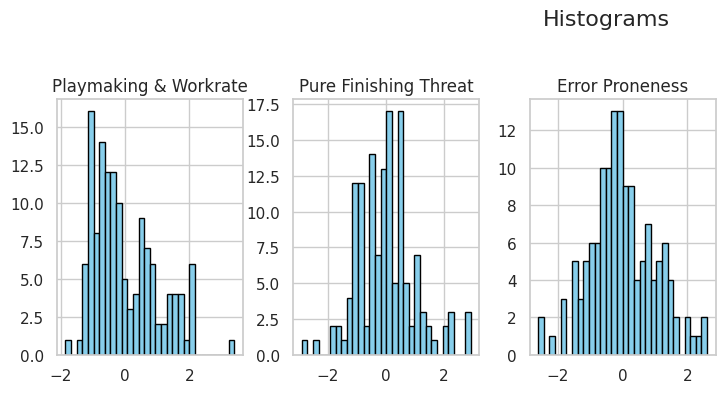

In [ ]:
#Plot histograms

sns.set(style="whitegrid")
factor_scores_df.hist(bins=30, figsize=(12, 4), layout=(1, 5), color='skyblue', edgecolor='black')
plt.suptitle('Histograms', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

###Outliers

In [ ]:
df_analysis = factor_scores_df.copy()

# --- PASSO 1: DETETAR E SEPARAR OUTLIERS (Método IQR) ---
Q1 = df_analysis.quantile(0.25)
Q3 = df_analysis.quantile(0.75)
IQR = Q3 - Q1

# Definição de Outlier: 1.5x o IQR (Podes aumentar para 2.0 se quiseres ser mais conservador)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Máscara: Quem é outlier em PELO MENOS UM fator?
is_outlier = ((df_analysis < limite_inferior) | (df_analysis > limite_superior)).any(axis=1)

# Separar os datasets
df_outliers = df_analysis[is_outlier].copy()
df_normais = df_analysis[~is_outlier].copy()

print(f"Total Jogadores: {len(df_analysis)}")
print(f"Jogadores Normais: {len(df_normais)}")
print(f"Outliers (Aliens): {len(df_outliers)}")
print("Lista de Aliens:", df_outliers.index.tolist())

Total Jogadores: 138
Jogadores Normais: 131
Outliers (Aliens): 7
Lista de Aliens: ['Jesper Lindstrøm', 'Franck Honorat', 'Omar Marmoush', 'Patrik Schick', "M'Bala Nzola", 'Ousmane Dembélé', 'Lamine Yamal']


In [ ]:
# 1. Ordenar: Põe os "Melhores" (Aliens Positivos) no topo para destaque
# Ordena por um dos teus fatores principais (ex: Finishing ou Playmaking)
# (Podes mudar 'Pure Finishing Threat' para o fator que preferires)
df_outliers_sorted = df_outliers.sort_values(by='Pure Finishing Threat', ascending=False)

print()

# 2. Apresentar a Tabela
# O comando display() deixa a tabela bonita no Google Colab/Jupyter
try:
    # Tenta usar o estilo visual (cores ajudam a ver onde o valor é extremo)
    display(df_outliers_sorted.style.background_gradient(cmap='coolwarm', axis=0))
except:
    # Fallback se não der para usar estilos
    print(df_outliers_sorted)

# 3. (Opcional) Guardar numa lista para usares no texto do report
threshold_alien = 1.5

aliens_mask = (df_outliers['Playmaking & Workrate'] > threshold_alien) | \
              (df_outliers['Pure Finishing Threat'] > threshold_alien)

# Separar os nomes
lista_aliens = df_outliers[aliens_mask].index.tolist()
lista_negativos = df_outliers[~aliens_mask].index.tolist()

print("-" * 30)
print(f"👽 Aliens ({len(lista_aliens)}): {', '.join(lista_aliens)}")
print(f"🔻 Negative Outliers ({len(lista_negativos)}): {', '.join(lista_negativos)}")
print("-" * 30)

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Omar Marmoush,2.128932,2.925051,2.475442
Ousmane Dembélé,2.065622,2.811699,0.133838
Patrik Schick,-1.079333,2.796960,-0.044956
Lamine Yamal,3.393932,0.206574,1.621513
M'Bala Nzola,-0.548236,-0.156836,2.612847
Franck Honorat,1.793703,-0.851557,-2.611771
Jesper Lindstrøm,0.617044,-2.899714,-0.090516


------------------------------
👽 Aliens (5): Franck Honorat, Omar Marmoush, Patrik Schick, Ousmane Dembélé, Lamine Yamal
🔻 Negative Outliers (2): Jesper Lindstrøm, M'Bala Nzola
------------------------------


### Clusters

#####Hierarchical Clustering

In [ ]:
factor_scores_df = factor_scores_df.drop(df_outliers.index, errors='ignore')
factor_scores_df

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Alexander Isak,0.228552,1.333308,0.165287
Antoine Semenyo,0.882376,-0.402355,1.152518
Beto,-1.105230,0.106233,2.302261
Brennan Johnson,0.483647,-0.175292,-1.779311
Bryan Mbeumo,1.073416,0.249362,-0.302900
...,...,...,...
Roberto Piccoli,-1.033843,-0.315771,0.642792
Romelu Lukaku,-0.385500,0.570464,-0.907927
Santiago Castro,-0.412686,-0.122919,1.154175


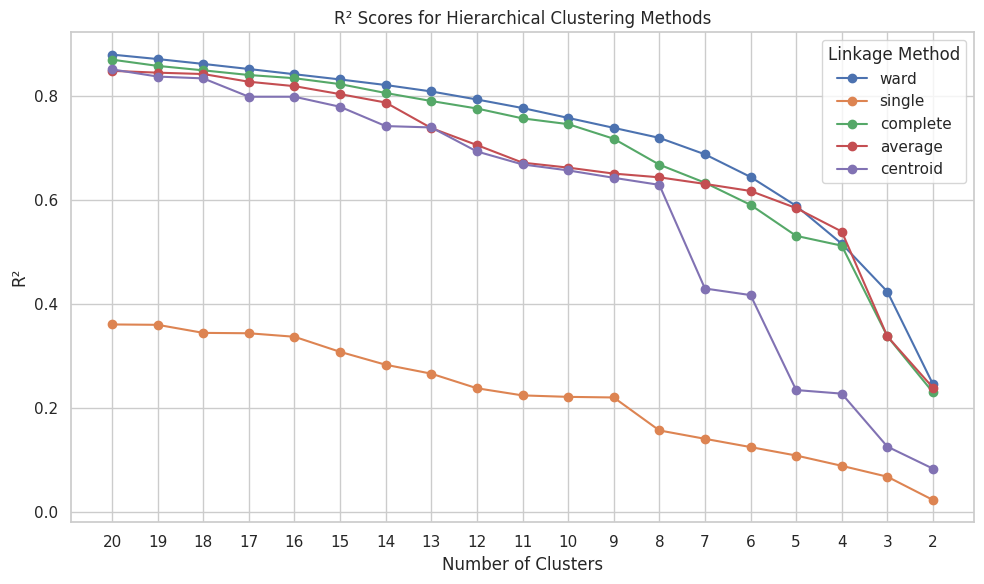

In [ ]:
#Choose the best hierarchical method

methods = ['ward', 'single', 'complete', 'average', 'centroid']
max_clusters = 20

grand_centroid = factor_scores_df.mean().values
tss = ((factor_scores_df.values - grand_centroid) ** 2).sum()

results = []

for method in methods:
    Z = linkage(factor_scores_df, method=method)

    for k in range(2, max_clusters + 1):
        labels = fcluster(Z, k, criterion='maxclust')


        wss = 0
        for cluster_id in np.unique(labels):
            cluster_points = factor_scores_df.values[labels == cluster_id]
            centroid = cluster_points.mean(axis=0)
            wss += ((cluster_points - centroid) ** 2).sum()

        r_squared = 1 - wss / tss
        results.append({'method': method, 'clusters': k, 'R_squared': r_squared})

df_r2 = pd.DataFrame(results, columns=['method', 'clusters', 'R_squared'])
df_pivot = df_r2.pivot(index='clusters', columns='method', values='R_squared')

#Plot
plt.figure(figsize=(10, 6))
for method in methods:
    plt.plot(df_pivot.index, df_pivot[method], marker='o', label=method)

plt.title('R² Scores for Hierarchical Clustering Methods')
plt.xlabel('Number of Clusters')
plt.ylabel('R²')
plt.xticks(df_pivot.index)
plt.legend(title='Linkage Method')
plt.grid(True)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

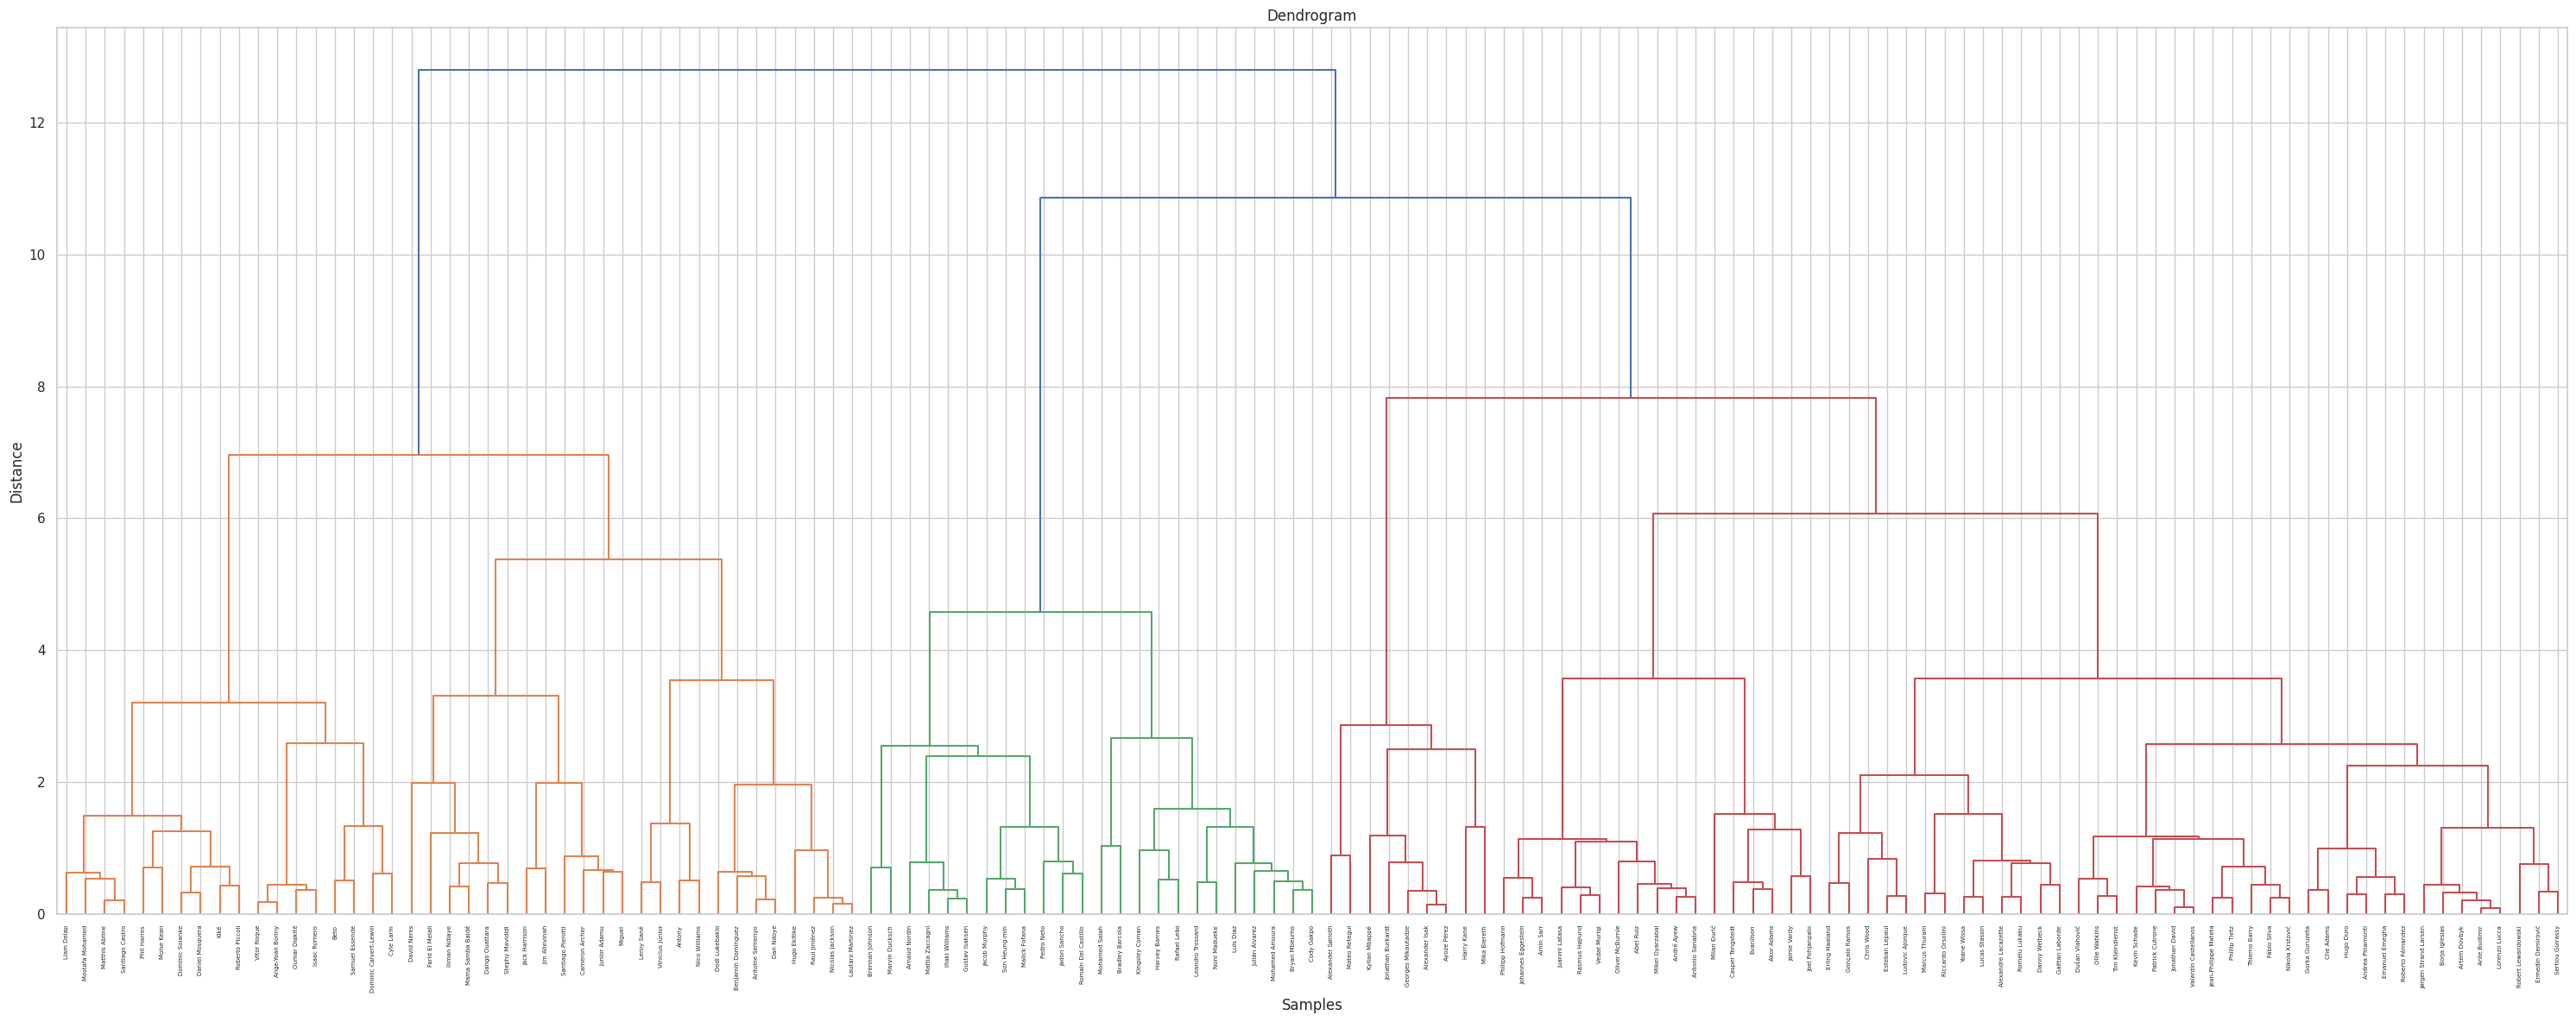

In [ ]:
#Dendrogram

Z = linkage(factor_scores_df, method='ward')

plt.figure(figsize=(30, 12))
dendrogram(Z, labels=factor_scores_df.index.tolist(), leaf_rotation=90)
plt.title("Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [ ]:
#Choose number of Clusters

n_clusters = 5

hierarchical_labels = fcluster(Z, n_clusters, criterion="maxclust")

In [ ]:
#Assign Cluster labels

df_8_original = factor_scores_df.copy()
df_8_original['Cluster'] = hierarchical_labels
df_8_original

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness,Cluster
Player,,,,
Alexander Isak,0.228552,1.333308,0.165287,4
Antoine Semenyo,0.882376,-0.402355,1.152518,2
Beto,-1.105230,0.106233,2.302261,1
Brennan Johnson,0.483647,-0.175292,-1.779311,3
Bryan Mbeumo,1.073416,0.249362,-0.302900,3
...,...,...,...,...
Roberto Piccoli,-1.033843,-0.315771,0.642792,1
Romelu Lukaku,-0.385500,0.570464,-0.907927,5
Santiago Castro,-0.412686,-0.122919,1.154175,1


In [ ]:
#Calculate cluster means

initial_seeds = df_8_original.groupby("Cluster").mean()
initial_seeds

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Cluster,,,
1,-0.729939,-0.277475,1.316926
2,0.599974,-0.778157,0.740704
3,1.150344,-0.177059,-0.760634
4,0.005781,1.834777,0.214091
5,-0.665936,0.117403,-0.522314


#####Non-hierarchical Clustering

In [ ]:
df_8_original = df_8_original.drop(columns=["Cluster"])
df_8_original

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
Player,,,
Alexander Isak,0.228552,1.333308,0.165287
Antoine Semenyo,0.882376,-0.402355,1.152518
Beto,-1.105230,0.106233,2.302261
Brennan Johnson,0.483647,-0.175292,-1.779311
Bryan Mbeumo,1.073416,0.249362,-0.302900
...,...,...,...
Roberto Piccoli,-1.033843,-0.315771,0.642792
Romelu Lukaku,-0.385500,0.570464,-0.907927
Santiago Castro,-0.412686,-0.122919,1.154175


In [ ]:
#Perform K-means

kmeans = KMeans(n_clusters = n_clusters, init=initial_seeds.values)
kmeans.fit(df_8_original)

KMeans(init=array([[-0.72993903, -0.27747504,  1.31692649],
       [ 0.59997401, -0.77815705,  0.74070355],
       [ 1.15034366, -0.17705896, -0.76063428],
       [ 0.00578128,  1.83477684,  0.21409148],
       [-0.66593601,  0.11740297, -0.52231359]]),
       n_clusters=5)

In [ ]:
#Assign Cluster Labels

df_8_original['kmeans_cluster'] = kmeans.labels_
df_8_original

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness,kmeans_cluster
Player,,,,
Alexander Isak,0.228552,1.333308,0.165287,3
Antoine Semenyo,0.882376,-0.402355,1.152518,1
Beto,-1.105230,0.106233,2.302261,0
Brennan Johnson,0.483647,-0.175292,-1.779311,2
Bryan Mbeumo,1.073416,0.249362,-0.302900,2
...,...,...,...,...
Roberto Piccoli,-1.033843,-0.315771,0.642792,0
Romelu Lukaku,-0.385500,0.570464,-0.907927,4
Santiago Castro,-0.412686,-0.122919,1.154175,0


In [ ]:
#R2

X = df_8_original.drop(columns=['kmeans_cluster']).values
X_pred = kmeans.cluster_centers_[kmeans.labels_]

r2 = explained_variance_score(X, X_pred)
print(f"Overall R²: {r2:.3f}")

Overall R²: 0.615


In [ ]:
#Compute R2 of each factor

X = df_8_original.drop(columns=['kmeans_cluster']).copy()
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

r2_per_factor = {}

for i, col in enumerate(X.columns):
    y_true = X[col].values
    y_pred = centroids[labels, i]

    r2 = explained_variance_score(y_true, y_pred)
    r2_per_factor[col] = round(r2, 4)

print("R² per Factor:")
for factor, r2 in r2_per_factor.items():
    print(f"  {factor}: {r2}")

R² per Factor:
  Playmaking & Workrate: 0.733
  Pure Finishing Threat: 0.4906
  Error Proneness: 0.6212


In [ ]:
#Group by cluster and compute means

cluster_means = df_8_original.groupby("kmeans_cluster").mean()
cluster_means

,Playmaking & Workrate,Pure Finishing Threat,Error Proneness
kmeans_cluster,,,
0,-0.632041,-0.441965,1.187215
1,0.910568,-0.777241,0.675451
2,1.136725,-0.157789,-0.863733
3,0.202041,1.752256,0.138066
4,-0.714118,0.092261,-0.498690


### Interpretation

####Data Prep

In [ ]:
aliens_cluster_labels = kmeans.predict(df_outliers)

# Atribuir os labels ao dataframe dos aliens
df_outliers['Cluster'] = aliens_cluster_labels

# --- PASSO 2: CRIAR A COLUNA 'TYPE' (Para os gráficos) ---
# Isto é crucial para saberes quem é quem no desenho
df_normais['Type'] = 'Normal'
df_outliers['Type'] = 'Alien'

# --- PASSO 3: JUNTAR TUDO (O Dataset Final) ---
df_final_completo = pd.concat([df_normais, df_outliers])

# (Opcional) Ordenar para ficar bonito
df_final_completo = df_final_completo.sort_index()

print("--- Reintegração Concluída ---")
print(f"Total Jogadores: {len(df_final_completo)}")
print(f"Aliens Reintegrados: {len(df_outliers)}")
print(df_outliers[['Cluster']]) # Mostra onde é que os Aliens caíram

--- Reintegração Concluída ---
Total Jogadores: 138
Aliens Reintegrados: 7
                  Cluster
Player                   
Jesper Lindstrøm        1
Franck Honorat          2
Omar Marmoush           3
Patrik Schick           3
M'Bala Nzola            0
Ousmane Dembélé         3
Lamine Yamal            1


In [ ]:
# 1. Garantir que os clusters estão atribuídos nos dataframes originais
df_normais['Cluster'] = kmeans.labels_
df_outliers['Cluster'] = aliens_cluster_labels

# 2. Garantir que o Tipo está atribuído
df_normais['Type'] = 'Normal'
df_outliers['Type'] = 'Alien'

# 3. Juntar (Concatenar)
df_final_completo = pd.concat([df_normais, df_outliers])

# 4. Preparar o dataset para os gráficos (df_plot)
df_plot = df_final_completo.copy().reset_index()

# Renomear a coluna do índice para 'Player'
# (Verifica qual o nome que aparece. Se o index não tinha nome, costuma ficar 'index')
if 'index' in df_plot.columns:
    df_plot = df_plot.rename(columns={'index': 'Player'})
else:
    # Se o nome for outro (ex: 'Equipa' ou vazio), renomeia a primeira coluna
    df_plot.rename(columns={df_plot.columns[0]: 'Player'}, inplace=True)

# 5. LIMPEZA FINAL CRUCIAL (O que resolve o "nan")
# Converter Cluster para inteiro e depois para string (remove "1.0")
# E preencher possíveis vazios
df_plot['Cluster'] = df_plot['Cluster'].fillna(-1).astype(int).astype(str)
df_plot['Type'] = df_plot['Type'].fillna('Normal')

print("Verificação de Clusters (Não deve haver 'nan'):")
print(df_plot['Cluster'].unique())

Verificação de Clusters (Não deve haver 'nan'):
['3' '1' '0' '2' '4']


In [ ]:
# Criar uma cópia para gráficos
df_plot = df_final_completo.copy()

# Reset ao index para o "Nome" passar a ser uma coluna
df_plot = df_plot.reset_index()
df_plot = df_plot.rename(columns={'index': 'Player'}) # O nome da coluna do index passa a ser 'Player'

# Garantir que o Cluster é texto (para cores discretas) e Type está preenchido
df_plot['Cluster'] = df_plot['Cluster'].astype(str)
df_plot['Type'] = df_plot['Type'].fillna('Normal')

print("Dados prontos para plotar!")
print(df_plot.head())

Dados prontos para plotar!
            Player  Playmaking & Workrate  Pure Finishing Threat  \
0   Alexander Isak               0.228552               1.333308   
1  Antoine Semenyo               0.882376              -0.402355   
2             Beto              -1.105230               0.106233   
3  Brennan Johnson               0.483647              -0.175292   
4     Bryan Mbeumo               1.073416               0.249362   

   Error Proneness    Type Cluster  
0         0.165287  Normal       3  
1         1.152518  Normal       1  
2         2.302261  Normal       0  
3        -1.779311  Normal       2  
4        -0.302900  Normal       2  


####Gráficos Com os Aliens

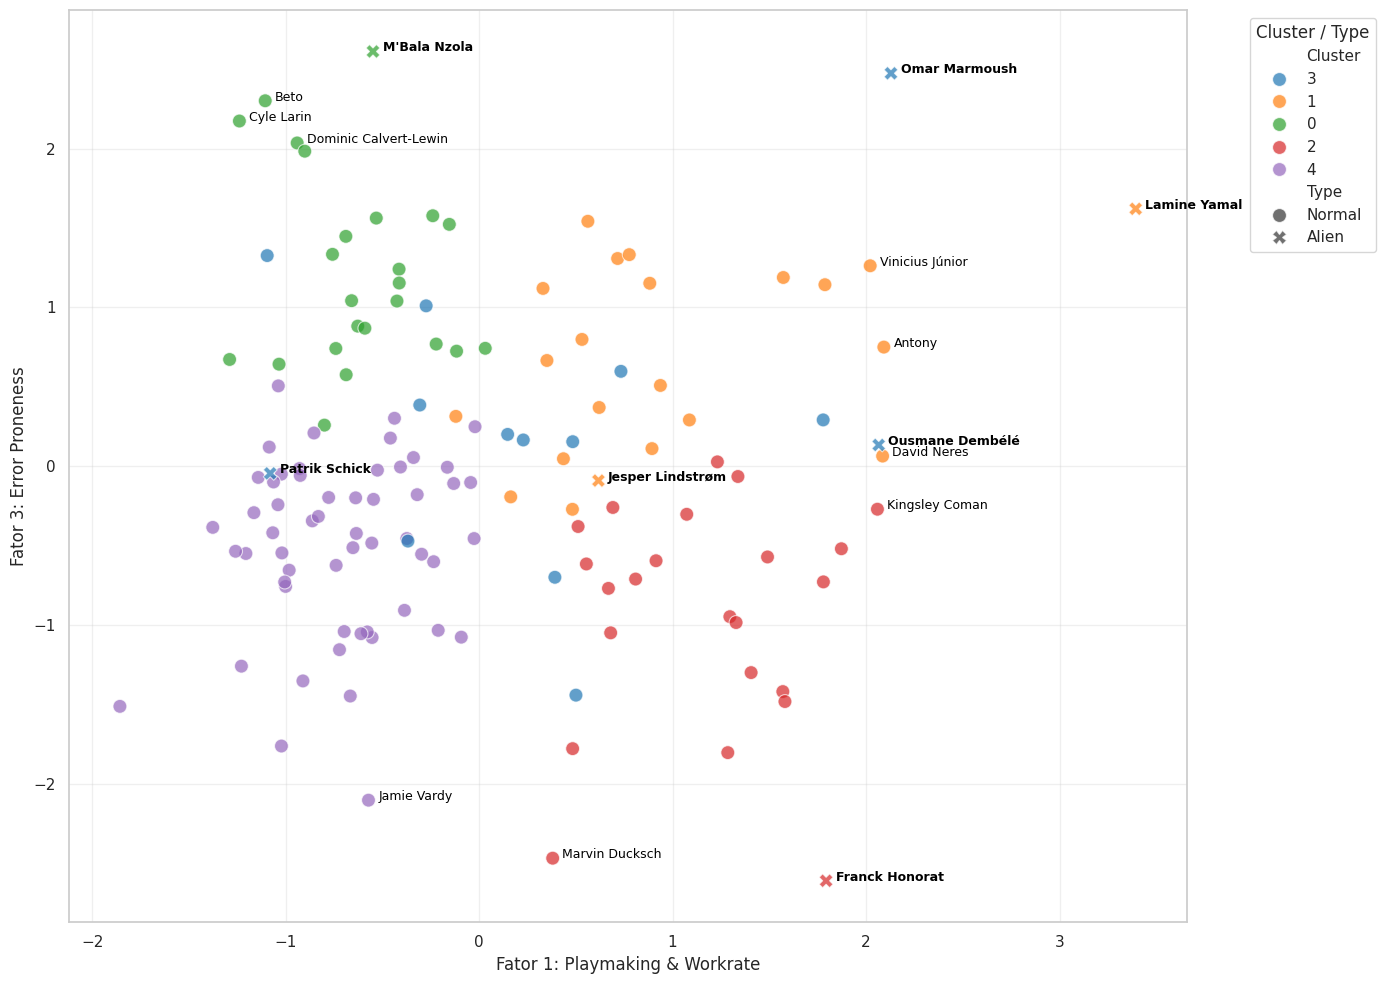

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Usar Seaborn é mais fácil que o loop manual do matplotlib para cores/estilos
sns.scatterplot(data=df_plot,
                x='Playmaking & Workrate',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                style='Type',        # Forma por Tipo (Alien vs Normal)
                palette='tab10',     # A paleta que querias
                s=100,               # Tamanho dos pontos
                alpha=0.7)

# Adicionar nomes (Filtro inteligente para não encavalitar tudo)
for i in range(df_plot.shape[0]):
    # Só mete nome se for Alien OU se for "extremo" nos eixos
    if (df_plot.iloc[i]['Type'] == 'Alien') or \
       (abs(df_plot.iloc[i]['Playmaking & Workrate']) > 2) or \
       (abs(df_plot.iloc[i]['Error Proneness']) > 2):

        plt.text(df_plot.iloc[i]['Playmaking & Workrate']+0.05,
                 df_plot.iloc[i]['Error Proneness'],
                 df_plot.iloc[i]['Player'],
                 fontsize=9,
                 color='black',
                 weight='bold' if df_plot.iloc[i]['Type'] == 'Alien' else 'normal')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 3: Error Proneness')
plt.legend(title='Cluster / Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

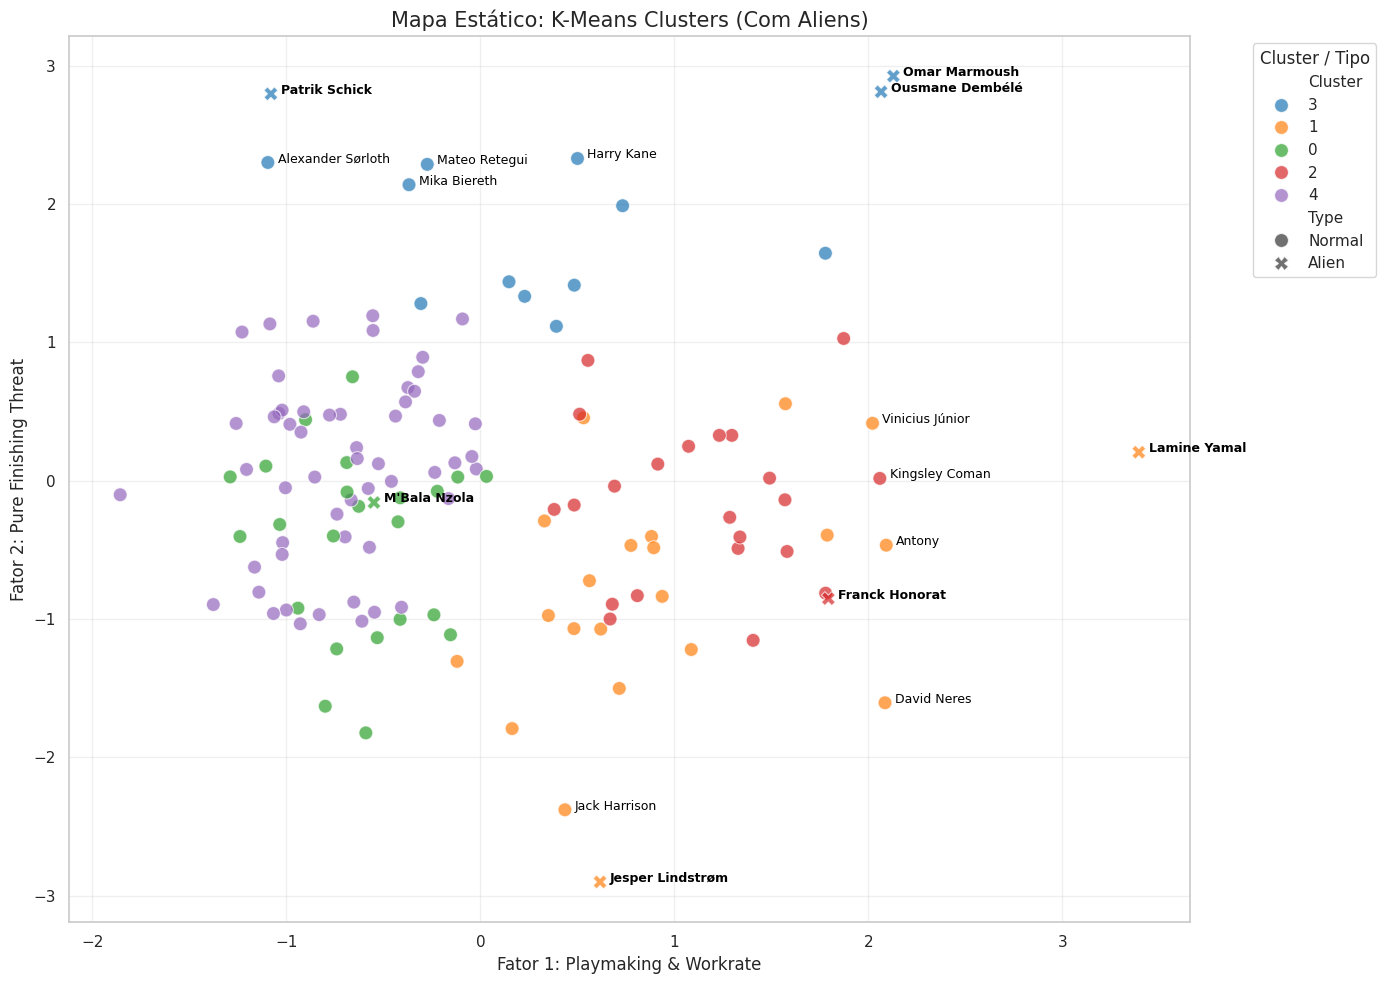

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Usar Seaborn é mais fácil que o loop manual do matplotlib para cores/estilos
sns.scatterplot(data=df_plot,
                x='Playmaking & Workrate',
                y='Pure Finishing Threat', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                style='Type',        # Forma por Tipo (Alien vs Normal)
                palette='tab10',     # A paleta que querias
                s=100,               # Tamanho dos pontos
                alpha=0.7)

# Adicionar nomes (Filtro inteligente para não encavalitar tudo)
for i in range(df_plot.shape[0]):
    # Só mete nome se for Alien OU se for "extremo" nos eixos
    if (df_plot.iloc[i]['Type'] == 'Alien') or \
       (abs(df_plot.iloc[i]['Playmaking & Workrate']) > 2) or \
       (abs(df_plot.iloc[i]['Pure Finishing Threat']) > 2):

        plt.text(df_plot.iloc[i]['Playmaking & Workrate']+0.05,
                 df_plot.iloc[i]['Pure Finishing Threat'],
                 df_plot.iloc[i]['Player'],
                 fontsize=9,
                 color='black',
                 weight='bold' if df_plot.iloc[i]['Type'] == 'Alien' else 'normal')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 2: Pure Finishing Threat')
plt.title('Mapa Estático: K-Means Clusters (Com Aliens)', fontsize=15)
plt.legend(title='Cluster / Tipo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

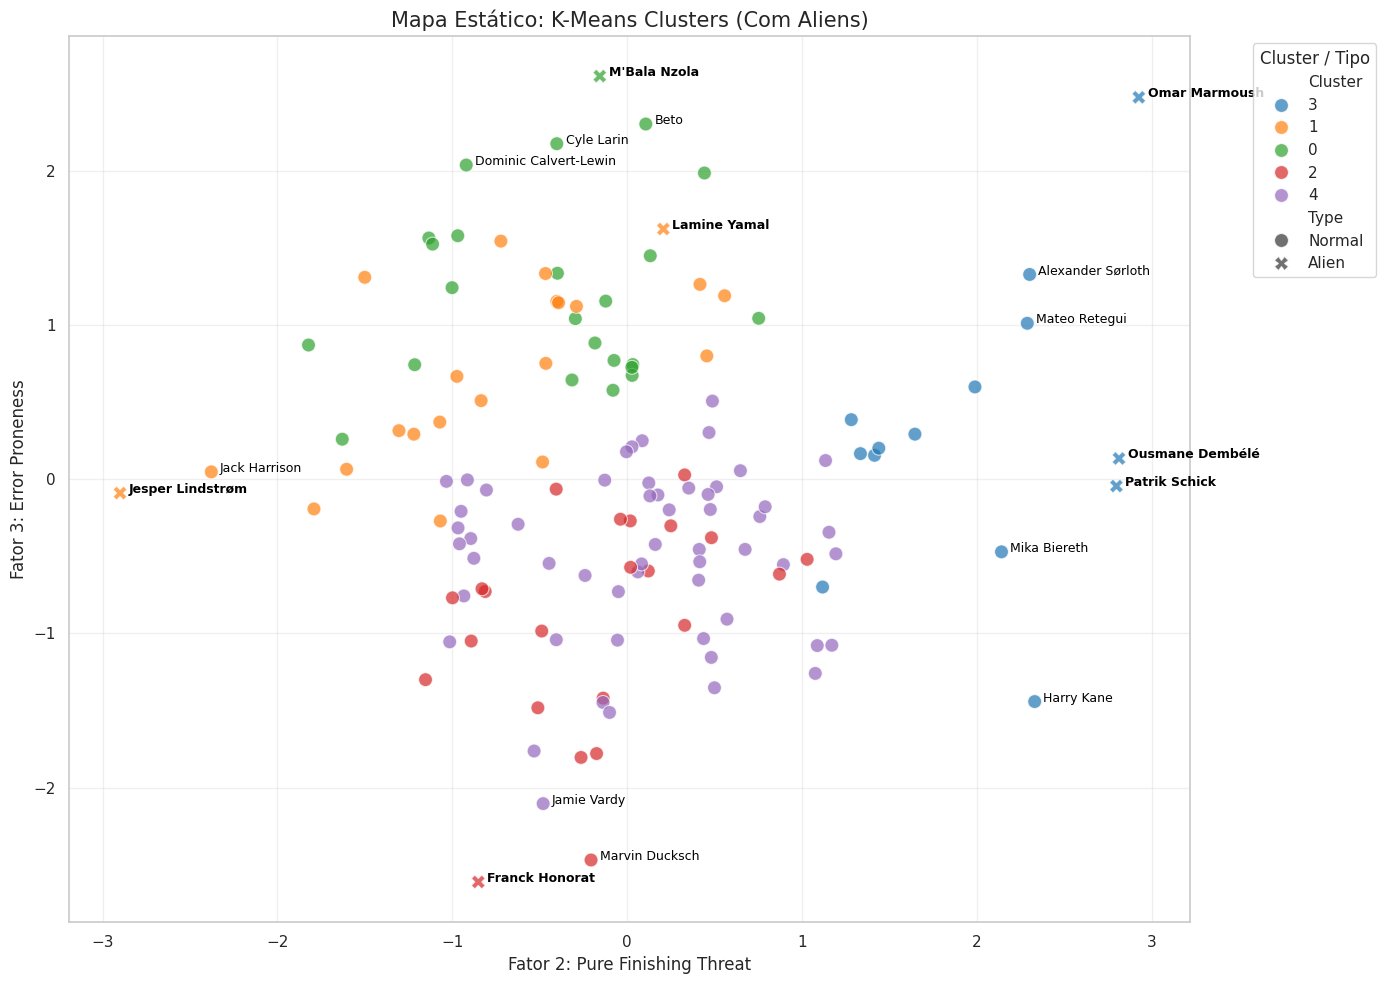

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# Usar Seaborn é mais fácil que o loop manual do matplotlib para cores/estilos
sns.scatterplot(data=df_plot,
                x='Pure Finishing Threat',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                style='Type',        # Forma por Tipo (Alien vs Normal)
                palette='tab10',     # A paleta que querias
                s=100,               # Tamanho dos pontos
                alpha=0.7)

# Adicionar nomes (Filtro inteligente para não encavalitar tudo)
for i in range(df_plot.shape[0]):
    # Só mete nome se for Alien OU se for "extremo" nos eixos
    if (df_plot.iloc[i]['Type'] == 'Alien') or \
       (abs(df_plot.iloc[i]['Pure Finishing Threat']) > 2) or \
       (abs(df_plot.iloc[i]['Error Proneness']) > 2):

        plt.text(df_plot.iloc[i]['Pure Finishing Threat']+0.05,
                 df_plot.iloc[i]['Error Proneness'],
                 df_plot.iloc[i]['Player'],
                 fontsize=9,
                 color='black',
                 weight='bold' if df_plot.iloc[i]['Type'] == 'Alien' else 'normal')

plt.xlabel('Fator 2: Pure Finishing Threat')
plt.ylabel('Fator 3: Error Proneness')
plt.title('Mapa Estático: K-Means Clusters (Com Aliens)', fontsize=15)
plt.legend(title='Cluster / Tipo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# 1. Criar uma coluna numérica para o tamanho (Truque para substituir o size_map)
# Normais = 10, Aliens = 25 (para se destacarem bem)
df_plot['Marker_Size'] = df_plot['Type'].map({'Normal': 10, 'Alien': 25})

# 2. Criar o Gráfico
fig = px.scatter(df_plot,
                 x='Playmaking & Workrate',
                 y='Pure Finishing Threat',
                 color='Cluster',

                 # SÍMBOLOS (Isto funciona)
                 symbol='Type',
                 symbol_map={'Normal': 'circle', 'Alien': 'star'},

                 # TAMANHO (A forma corrigida)
                 size='Marker_Size',
                 size_max=20, # Define o tamanho máximo das bolhas no ecrã

                 hover_name='Player',
                 hover_data=['Type'],

                 template='plotly_dark',
                 width=1100,
                 height=750)

# Design
fig.update_traces(marker=dict(line=dict(width=1, color='White')))
fig.update_layout(
    legend_title_text='Tatical Profile',
    xaxis_title='Fator 1: Playmaking & Workrate',
    yaxis_title='Fator 2: Pure Finishing Threat'
)

fig.show()

In [ ]:
# 1. Criar uma coluna numérica para o tamanho (Truque para substituir o size_map)
# Normais = 10, Aliens = 25 (para se destacarem bem)
df_plot['Marker_Size'] = df_plot['Type'].map({'Normal': 10, 'Alien': 25})

# 2. Criar o Gráfico
fig = px.scatter(df_plot,
                 x='Playmaking & Workrate',
                 y='Error Proneness',
                 color='Cluster',

                 # SÍMBOLOS (Isto funciona)
                 symbol='Type',
                 symbol_map={'Normal': 'circle', 'Alien': 'star'},

                 # TAMANHO (A forma corrigida)
                 size='Marker_Size',
                 size_max=20, # Define o tamanho máximo das bolhas no ecrã

                 hover_name='Player',
                 hover_data=['Type'],
                 title='<b>Mapa Interativo dos Perfis (Passa o rato!)</b>',
                 template='plotly_dark',
                 width=1100,
                 height=750)

# Design
fig.update_traces(marker=dict(line=dict(width=1, color='White')))
fig.update_layout(
    legend_title_text='Perfil Tático',
    xaxis_title='Fator 1: Playmaking & Workrate',
    yaxis_title='Fator 3: Error Proneness'
)

fig.show()

In [ ]:
# 1. Criar uma coluna numérica para o tamanho (Truque para substituir o size_map)
# Normais = 10, Aliens = 25 (para se destacarem bem)
df_plot['Marker_Size'] = df_plot['Type'].map({'Normal': 10, 'Alien': 25})

# 2. Criar o Gráfico
fig = px.scatter(df_plot,
                 x='Pure Finishing Threat',
                 y='Error Proneness',
                 color='Cluster',

                 # SÍMBOLOS (Isto funciona)
                 symbol='Type',
                 symbol_map={'Normal': 'circle', 'Alien': 'star'},

                 # TAMANHO (A forma corrigida)
                 size='Marker_Size',
                 size_max=20, # Define o tamanho máximo das bolhas no ecrã

                 hover_name='Player',
                 hover_data=['Type'],
                 title='<b>Mapa Interativo dos Perfis (Passa o rato!)</b>',
                 template='plotly_dark',
                 width=1100,
                 height=750)

# Design
fig.update_traces(marker=dict(line=dict(width=1, color='White')))
fig.update_layout(
    legend_title_text='Perfil Tático',
    xaxis_title='Fator 2: Pure Finishing Threat',
    yaxis_title='Fator 3: Error Proneness'
)

fig.show()

####Gráficos sem os aliens

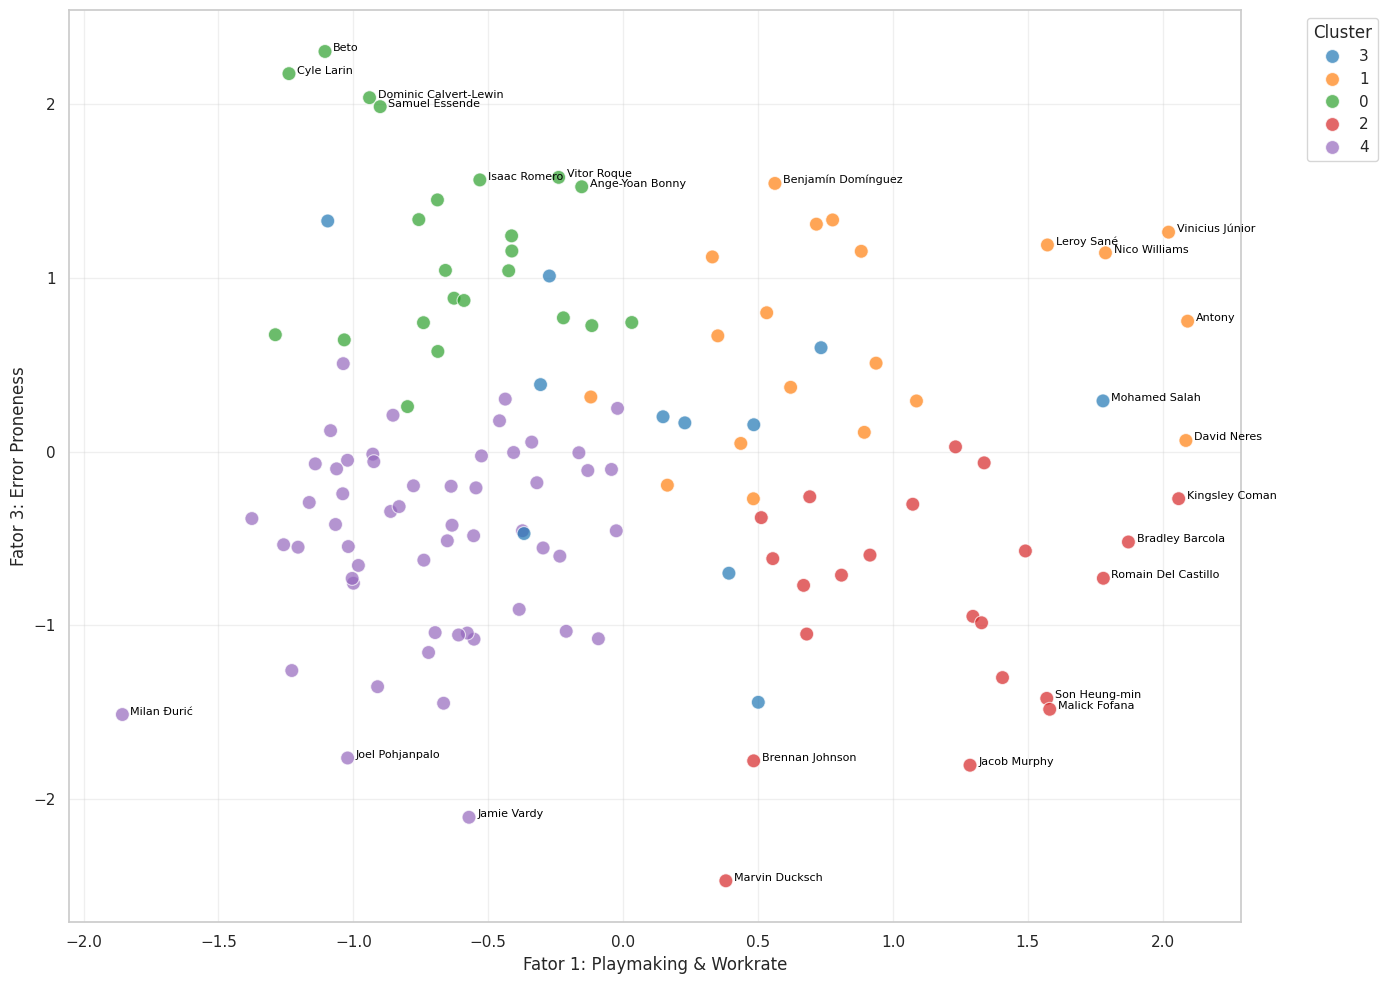

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

# --- FILTRAR SÓ OS NORMAIS ---
df_zoom = df_plot[df_plot['Type'] == 'Normal'].copy()

# Usar Seaborn
sns.scatterplot(data=df_zoom,
                x='Playmaking & Workrate',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                # style='Type',      # Removemos o style porque agora são todos 'Normal'
                palette='tab10',
                s=100,
                alpha=0.7)

# Adicionar nomes (Filtro ajustado para mostrar os destaques "humanos")
for i in range(df_zoom.shape[0]):
    # Mostra nome se for extremo DENTRO da escala normal (> 1.5 ou < -1.5)
    if (abs(df_zoom.iloc[i]['Playmaking & Workrate']) > 1.5) or \
       (abs(df_zoom.iloc[i]['Error Proneness']) > 1.5):

        plt.text(df_zoom.iloc[i]['Playmaking & Workrate']+0.03,
                 df_zoom.iloc[i]['Error Proneness'],
                 df_zoom.iloc[i]['Player'],
                 fontsize=8,
                 color='black')

plt.xlabel('Fator 1: Playmaking & Workrate')
plt.ylabel('Fator 3: Error Proneness')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

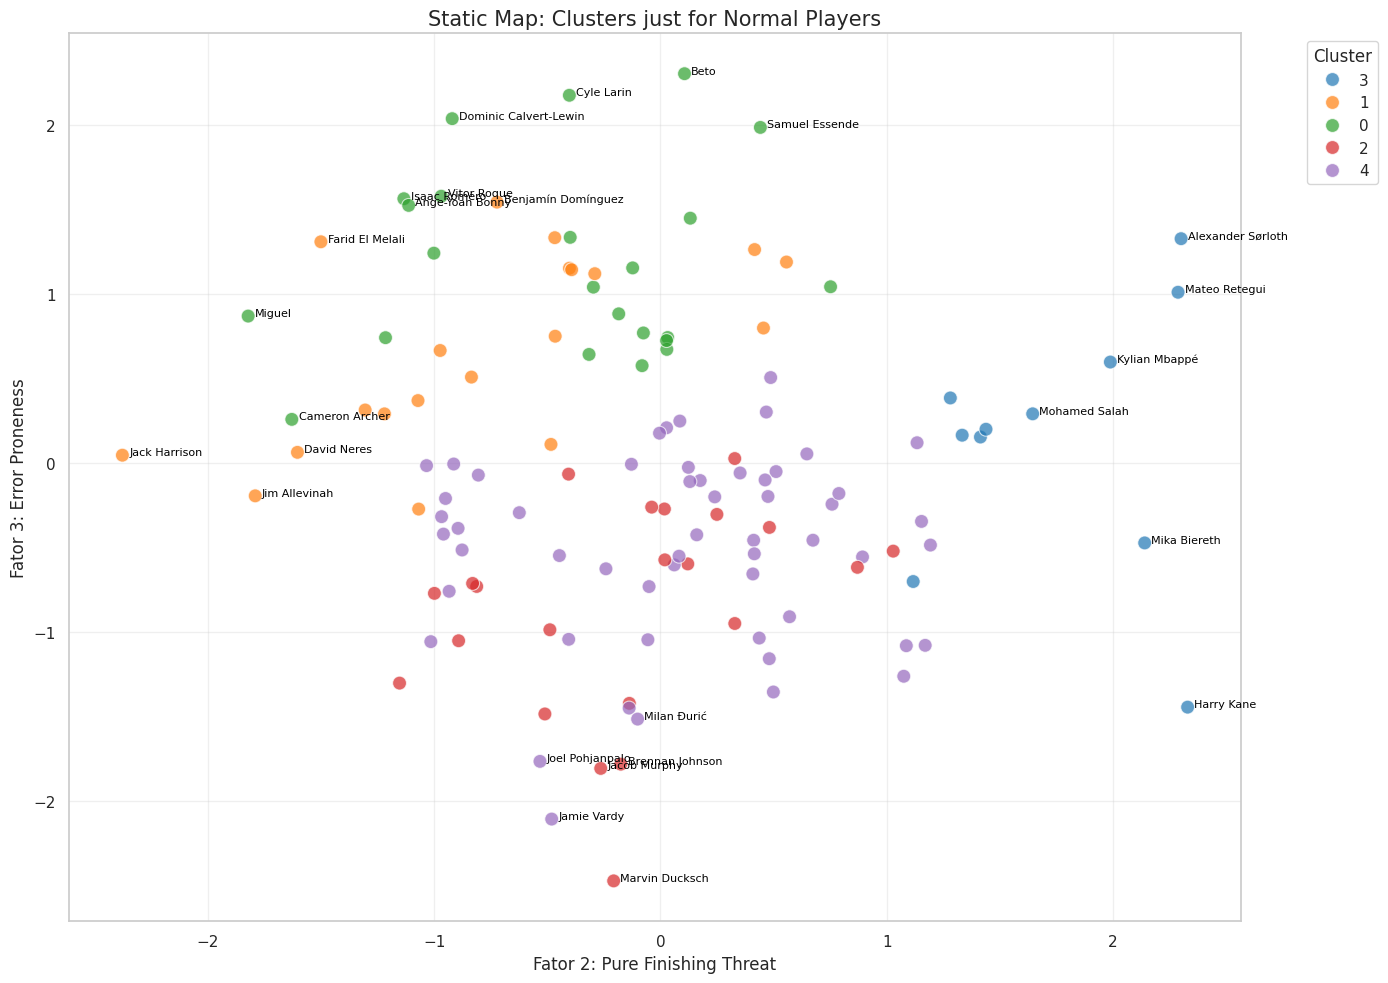

In [ ]:
plt.figure(figsize=(14, 10))

# --- FILTRAR SÓ OS NORMAIS ---
df_zoom = df_plot[df_plot['Type'] == 'Normal'].copy()

# Usar Seaborn
sns.scatterplot(data=df_zoom,
                x='Pure Finishing Threat',
                y='Error Proneness', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                # style='Type',      # Removemos o style porque agora são todos 'Normal'
                palette='tab10',
                s=100,
                alpha=0.7)

# Adicionar nomes (Filtro ajustado para mostrar os destaques "humanos")
for i in range(df_zoom.shape[0]):
    # Mostra nome se for extremo DENTRO da escala normal (> 1.5 ou < -1.5)
    if (abs(df_zoom.iloc[i]['Pure Finishing Threat']) > 1.5) or \
       (abs(df_zoom.iloc[i]['Error Proneness']) > 1.5):

        plt.text(df_zoom.iloc[i]['Pure Finishing Threat']+0.03,
                 df_zoom.iloc[i]['Error Proneness'],
                 df_zoom.iloc[i]['Player'],
                 fontsize=8,
                 color='black')

plt.xlabel('Fator 2: Pure Finishing Threat')
plt.ylabel('Fator 3: Error Proneness')
plt.title('Static Map: Clusters just for Normal Players', fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

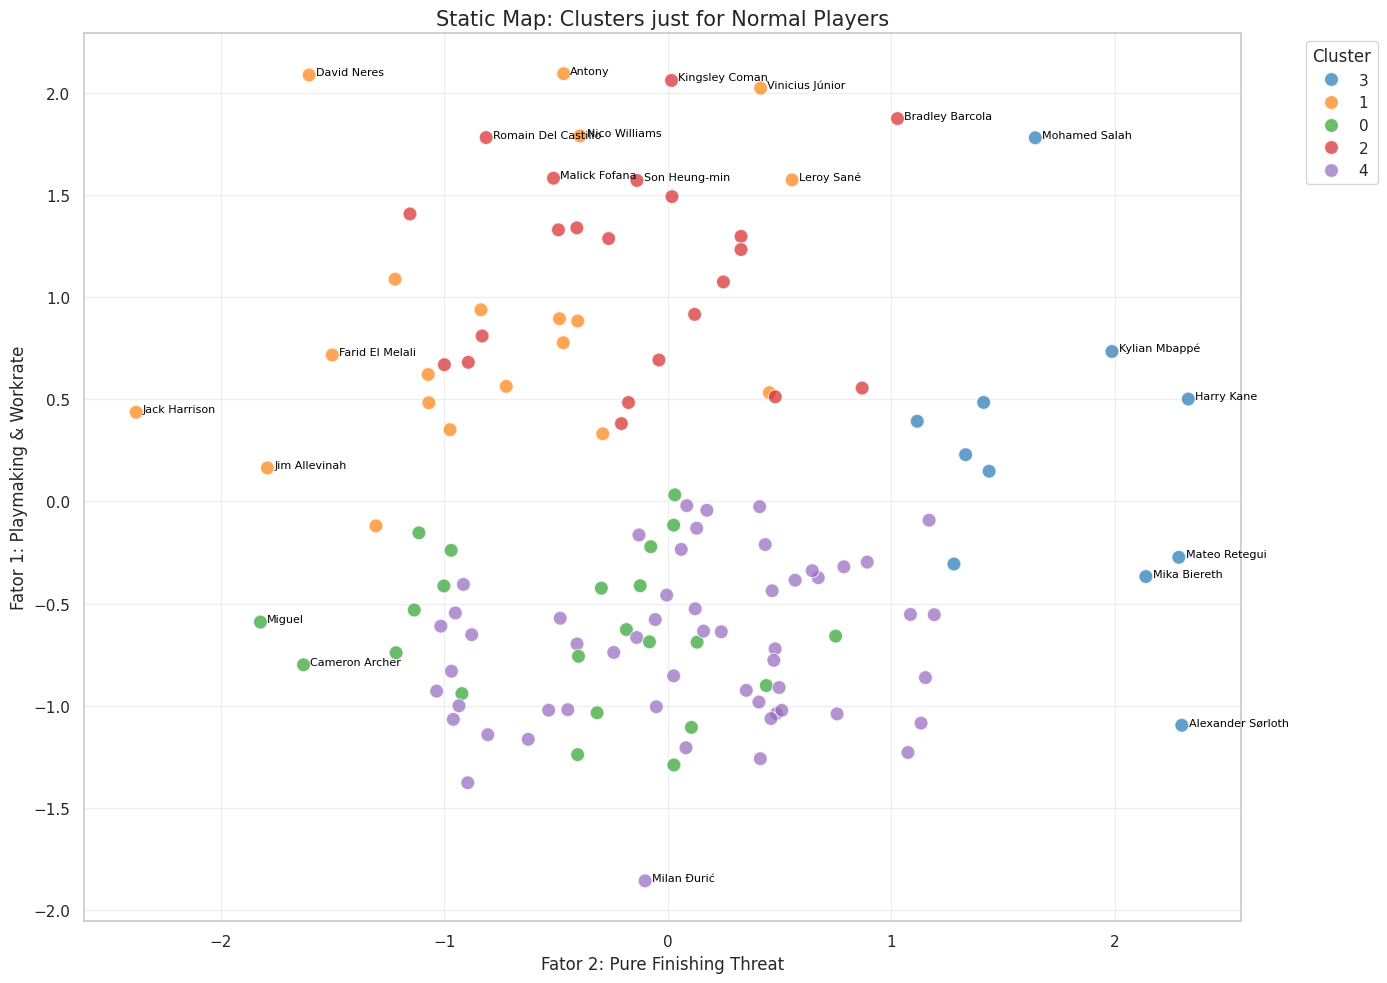

In [ ]:
plt.figure(figsize=(14, 10))

# --- FILTRAR SÓ OS NORMAIS ---
df_zoom = df_plot[df_plot['Type'] == 'Normal'].copy()

# Usar Seaborn
sns.scatterplot(data=df_zoom,
                x='Pure Finishing Threat',
                y='Playmaking & Workrate', # O eixo que pediste
                hue='Cluster',       # Cor por Cluster
                # style='Type',      # Removemos o style porque agora são todos 'Normal'
                palette='tab10',
                s=100,
                alpha=0.7)

# Adicionar nomes (Filtro ajustado para mostrar os destaques "humanos")
for i in range(df_zoom.shape[0]):
    # Mostra nome se for extremo DENTRO da escala normal (> 1.5 ou < -1.5)
    if (abs(df_zoom.iloc[i]['Pure Finishing Threat']) > 1.5) or \
       (abs(df_zoom.iloc[i]['Playmaking & Workrate']) > 1.5):

        plt.text(df_zoom.iloc[i]['Pure Finishing Threat']+0.03,
                 df_zoom.iloc[i]['Playmaking & Workrate'],
                 df_zoom.iloc[i]['Player'],
                 fontsize=8,
                 color='black')

plt.xlabel('Fator 2: Pure Finishing Threat')
plt.ylabel('Fator 1: Playmaking & Workrate')
plt.title('Static Map: Clusters just for Normal Players', fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Preparar os dados: Vamos fazer reset ao index para o "Nome" passar a ser uma coluna normal
# Isto cria uma coluna chamada 'index' (ou o nome que tinhas) com os nomes dos jogadores
df_interativo = factor_scores_df.reset_index()

# Garante que a coluna dos nomes se chama 'Player' (ajusta se necessário)
df_interativo = df_interativo.rename(columns={'index': 'Player', 'Equipa': 'Player'})
# (Nota: O pandas dá o nome 'index' por defeito se o index não tiver nome)

# Merge kmeans_cluster from df_8_original into df_interativo
df_interativo = df_interativo.merge(df_8_original['kmeans_cluster'], left_on='Player', right_index=True)
df_interativo = df_interativo.rename(columns={'kmeans_cluster': 'Cluster'})

# 2. Criar o Gráfico Mágico
fig = px.scatter(df_interativo,
                 x='Playmaking & Workrate',
                 y='Pure Finishing Threat',
                 color='Cluster',
                 hover_name='Player', # <--- AQUI ESTÁ A MAGIA! (Mostra o nome ao passar o rato)
                 title='Mapa Interativo dos Perfis (Passa o rato nos pontos!)',
                 template='plotly_dark', # Fica com um look "pro" escuro
                 width=1000,
                 height=700)

# 3. Melhorar o design (opcional, mas fica top)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend_title_text='Perfil Tático')

# 4. Mostrar
fig.show()

In [ ]:
# 1. Preparar os dados: Vamos fazer reset ao index para o "Nome" passar a ser uma coluna normal
# Isto cria uma coluna chamada 'index' (ou o nome que tinhas) com os nomes dos jogadores
df_interativo = factor_scores_df.reset_index()

# Garante que a coluna dos nomes se chama 'Player' (ajusta se necessário)
df_interativo = df_interativo.rename(columns={'index': 'Player', 'Equipa': 'Player'})
# (Nota: O pandas dá o nome 'index' por defeito se o index não tiver nome)

# Merge kmeans_cluster from df_8_original into df_interativo
df_interativo = df_interativo.merge(df_8_original['kmeans_cluster'], left_on='Player', right_index=True)
df_interativo = df_interativo.rename(columns={'kmeans_cluster': 'Cluster'})

# 2. Criar o Gráfico Mágico
fig = px.scatter(df_interativo,
                 x='Playmaking & Workrate',
                 y='Error Proneness',
                 color='Cluster',
                 hover_name='Player', # <--- AQUI ESTÁ A MAGIA! (Mostra o nome ao passar o rato)
                 title='Mapa Interativo dos Perfis (Passa o rato nos pontos!)',
                 template='plotly_dark', # Fica com um look "pro" escuro
                 width=1000,
                 height=700)

# 3. Melhorar o design (opcional, mas fica top)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend_title_text='Perfil Tático')

# 4. Mostrar
fig.show()

In [ ]:
# 1. Preparar os dados: Vamos fazer reset ao index para o "Nome" passar a ser uma coluna normal
# Isto cria uma coluna chamada 'index' (ou o nome que tinhas) com os nomes dos jogadores
df_interativo = factor_scores_df.reset_index()

# Garante que a coluna dos nomes se chama 'Player' (ajusta se necessário)
df_interativo = df_interativo.rename(columns={'index': 'Player', 'Equipa': 'Player'})
# (Nota: O pandas dá o nome 'index' por defeito se o index não tiver nome)

# Merge kmeans_cluster from df_8_original into df_interativo
df_interativo = df_interativo.merge(df_8_original['kmeans_cluster'], left_on='Player', right_index=True)
df_interativo = df_interativo.rename(columns={'kmeans_cluster': 'Cluster'})

# 2. Criar o Gráfico Mágico
fig = px.scatter(df_interativo,
                 x='Pure Finishing Threat',
                 y='Error Proneness',
                 color='Cluster',
                 hover_name='Player', # <--- AQUI ESTÁ A MAGIA! (Mostra o nome ao passar o rato)
                 title='Mapa Interativo dos Perfis (Passa o rato nos pontos!)',
                 template='plotly_dark', # Fica com um look "pro" escuro
                 width=1000,
                 height=700)

# 3. Melhorar o design (opcional, mas fica top)
fig.update_traces(marker=dict(size=10, line=dict(width=1, color='DarkSlateGrey')))
fig.update_layout(legend_title_text='Perfil Tático')

# 4. Mostrar
fig.show()